# Part II · Notebook 01 — X5: replication on four new datasets and an autoregressive-transformer generator

**Questions.** (1) Do Part I's findings hold on data the audit was not designed on? (2) Where does a GReaT-style
autoregressive transformer, which models each row as a sequence of column tokens, sit on the privacy–utility plane?

**Design.** COMPAS (criminal justice), Taiwan credit default, Portuguese bank marketing and Diabetes-130 hospital
readmissions; 3 seeds each; all ten mechanisms (Part I's nine + AR-Transformer). The AR-Transformer is also run on
Part I's four datasets with Part I's seeds, so it can be compared everywhere. Hypothesis H13 is tested in Notebook 05.

In [1]:
import os, time, json, gc, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import sdaudit as sa
QUICK = os.environ.get("QUICK", "0") == "1"
if QUICK: sa.CFG.update(ctgan_epochs=3, tvae_epochs=3, ddpm_steps=50, ar_steps=30)
OUT = "outputs2"; os.makedirs(f"{OUT}/tables", exist_ok=True); os.makedirs(f"{OUT}/figures", exist_ok=True); os.makedirs(f"{OUT}/synthetic", exist_ok=True)
sns.set_theme(style="whitegrid", context="paper", font_scale=1.1); plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
T0 = time.time()
NEW = ["compas", "credit", "bank", "diabetes"]; OLD = {"adult": [0, 1, 2], "german": [0, 1, 2, 3, 4], "fraud": [0, 1, 2], "pima": [0, 1, 2, 3, 4]}
SEEDS_NEW = [0, 1, 2] if not QUICK else [0]
if QUICK: OLD = {"german": [0]}; NEW = ["compas"]
GENS = list(sa.GENERATORS)
print("mechanisms:", GENS)

mechanisms: ['Identity', 'Independent', 'GaussianCopula', 'CART', 'CTGAN', 'TVAE', 'DDPM', 'AR-Transformer', 'MST (ε=1)', 'k-anon (k=10)']


In [2]:
RES = f"{OUT}/tables/X5_results.csv"; rows = []
def run_one(key, df, meta, seed, gname, tr, ho, te, real):
    raw, cost = sa.measured(sa.GENERATORS[gname], tr, meta, seed)
    syn = sa.postprocess(raw, tr, meta)
    r, _ = sa.evaluate_release(tr, ho, te, syn, meta, seed, real=real)
    r.update(dataset=meta["name"], key=key, seed=seed, generator=gname, family=sa.FAMILY[gname], **{f"gen_{k}": v for k, v in cost.items()})
    if seed == 0: syn.to_csv(f"{OUT}/synthetic/{meta['name']}_{gname.split(' ')[0]}_seed0.csv", index=False)
    return r

jobs = [(k, s, g) for k in NEW for s in SEEDS_NEW for g in GENS] + [(k, s, "AR-Transformer") for k, ss in OLD.items() for s in ss]
cache = {}
for i, (key, seed, g) in enumerate(jobs, 1):
    if key not in cache: cache = {key: sa.load(key)}
    df, meta = cache[key]; tr, ho, te = sa.make_split(df, meta, seed)
    u_r, p_r = sa.utility(tr, te, meta, seed); real = (u_r, sa.fairness(tr, te, p_r["HGB"], meta))
    t0 = time.time(); r = run_one(key, df, meta, seed, g, tr, ho, te, real); r["real_auc_mean"] = u_r["auc_mean"]; rows.append(r)
    pd.DataFrame(rows).to_csv(RES, index=False); gc.collect()
    print(f"[{i:>3}/{len(jobs)}] {meta['name']:<11} s{seed} {g:<15} U={r['util_ratio']:.3f} pair={r['pair']:.3f} MIA={r['mia_auc_max']:.3f} "
          f"TPR1={r['mia_tpr1_max']:.3f} link={r['anon_link']:.3f} | {time.time()-t0:.0f}s", flush=True)
X5 = pd.DataFrame(rows); print(f"done: {len(X5)} runs in {(time.time()-T0)/60:.1f} min")

[  1/136] COMPAS      s0 Identity        U=1.000 pair=1.000 MIA=0.799 TPR1=0.026 link=0.168 | 18s


[  2/136] COMPAS      s0 Independent     U=0.651 pair=0.965 MIA=0.513 TPR1=0.010 link=0.033 | 14s


[  3/136] COMPAS      s0 GaussianCopula  U=0.893 pair=0.909 MIA=0.508 TPR1=0.012 link=0.000 | 22s


[  4/136] COMPAS      s0 CART            U=0.974 pair=0.982 MIA=0.604 TPR1=0.026 link=0.090 | 12s


[  5/136] COMPAS      s0 CTGAN           U=0.816 pair=0.907 MIA=0.516 TPR1=0.011 link=0.012 | 59s


Reached maximum number of attempts 2000000 when generating singling out queries. Returning 173 instead of the requested 500.


... (137 outputs left out)

[134/136] Pima        s2 AR-Transformer  U=0.971 pair=0.827 MIA=0.760 TPR1=0.528 link=0.535 | 69s


[135/136] Pima        s3 AR-Transformer  U=0.986 pair=0.824 MIA=0.784 TPR1=0.544 link=0.626 | 70s


[136/136] Pima        s4 AR-Transformer  U=0.985 pair=0.848 MIA=0.815 TPR1=0.583 link=0.641 | 68s


done: 136 runs in 154.4 min


## Utility on the new datasets

In [3]:
N = X5[X5.key.isin(NEW)]; ORDER = GENS
def mci(x): return f"{np.mean(x):.3f} ± {sa.ci_t(x):.3f}" if len(x) > 1 else f"{np.mean(x):.3f}"
tu = N.pivot_table(index="generator", columns="dataset", values="util_ratio", aggfunc=mci).reindex(ORDER)
pooled = {g: sa.boot_ci(N[N.generator == g].util_ratio.values, groups=N[N.generator == g].dataset.values) for g in ORDER}
tu["pooled [95% CI]"] = [f"{pooled[g][0]:.3f} [{pooled[g][1]:.3f}, {pooled[g][2]:.3f}]" for g in tu.index]
tu.to_csv(f"{OUT}/tables/X5_utility_new.csv"); tu

dataset,Bank,COMPAS,Credit,Diabetes130,pooled [95% CI]
generator,,,,,
Identity,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,"1.000 [1.000, 1.000]"
Independent,0.592 ± 0.054,0.681 ± 0.209,0.729 ± 0.141,0.880 ± 0.029,"0.720 [0.698, 0.745]"
GaussianCopula,0.827 ± 0.082,0.936 ± 0.093,0.882 ± 0.047,0.922 ± 0.101,"0.892 [0.877, 0.907]"
CART,0.963 ± 0.015,0.981 ± 0.014,0.980 ± 0.009,0.973 ± 0.037,"0.974 [0.970, 0.978]"
CTGAN,0.783 ± 0.074,0.850 ± 0.098,0.808 ± 0.073,0.877 ± 0.040,"0.830 [0.816, 0.843]"
TVAE,0.929 ± 0.038,0.947 ± 0.060,0.972 ± 0.043,0.892 ± 0.140,"0.935 [0.921, 0.951]"
DDPM,0.897 ± 0.030,0.996 ± 0.008,0.968 ± 0.038,0.922 ± 0.063,"0.946 [0.938, 0.953]"
AR-Transformer,0.979 ± 0.012,0.991 ± 0.020,0.984 ± 0.027,0.993 ± 0.061,"0.987 [0.980, 0.993]"
MST (ε=1),0.684 ± 0.190,0.589 ± 0.120,0.748 ± 0.052,0.942 ± 0.034,"0.741 [0.719, 0.761]"


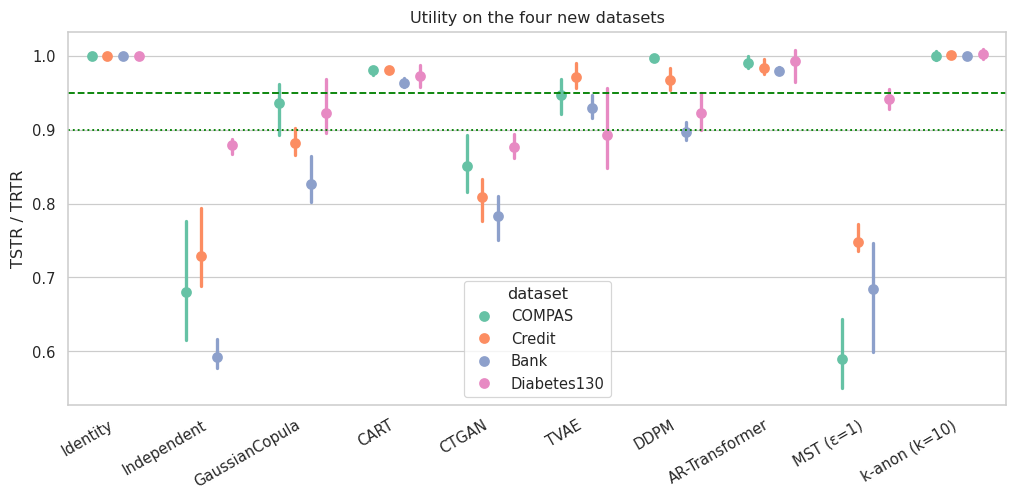

In [4]:
fig, ax = plt.subplots(figsize=(11, 4.4))
sns.pointplot(data=N, x="generator", y="util_ratio", hue="dataset", order=ORDER, dodge=0.5 if N.dataset.nunique() > 1 else False, linestyles="none", errorbar=("ci", 95), ax=ax, palette="Set2")
ax.axhline(0.9, ls=":", c="green"); ax.axhline(0.95, ls="--", c="green"); ax.set_xlabel(""); ax.set_ylabel("TSTR / TRTR"); ax.set_title("Utility on the four new datasets")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right"); fig.savefig(f"{OUT}/figures/X5_utility_new.png"); plt.show()

## Privacy on the new datasets (test of Part I's claim C1 on new data)

In [5]:
tp = N.groupby("generator")[["exact_match_syn", "dcr_share", "mia_auc_A1_distance", "mia_auc_A2_density_ratio", "mia_auc_A3_classifier_ratio",
                             "mia_auc_max", "mia_tpr1_max", "mia_auc_outlier", "mia_auc_inlier", "anon_singling", "anon_link", "anon_infer"]].mean().reindex(ORDER)
tp.to_csv(f"{OUT}/tables/X5_privacy_new.csv")
tests = []
for g in ORDER:
    s = N[N.generator == g]
    for a in ["A1_distance", "A2_density_ratio", "A3_classifier_ratio"]:
        d = s[f"mia_auc_{a}"].values - 0.5
        tests.append(dict(generator=g, attack=a, mean_auc=d.mean() + 0.5, p=stats.wilcoxon(d, alternative="greater").pvalue if np.any(d != 0) else 1.0))
TT = pd.DataFrame(tests); TT["p_holm"] = sa.holm(TT.p); TT["significant"] = TT.p_holm < 0.05; TT.to_csv(f"{OUT}/tables/X5_mia_tests_new.csv", index=False)
display(TT.pivot(index="generator", columns="attack", values="p_holm").reindex(ORDER).map(lambda p: f"{p:.2e}"))
tp.round(3)

attack,A1_distance,A2_density_ratio,A3_classifier_ratio
generator,,,
Identity,7.32e-03,7.32e-03,7.32e-03
Independent,1.00e+00,1.00e+00,2.08e-02
GaussianCopula,5.08e-01,8.14e-01,5.08e-01
CART,7.32e-03,7.32e-03,7.32e-03
CTGAN,1.00e+00,1.00e+00,4.48e-01
TVAE,4.48e-01,5.08e-01,4.48e-01
DDPM,3.19e-01,3.91e-02,7.32e-03
AR-Transformer,7.32e-03,7.32e-03,7.32e-03
MST (ε=1),1.00e+00,1.00e+00,1.00e+00


,exact_match_syn,dcr_share,mia_auc_A1_distance,mia_auc_A2_density_ratio,mia_auc_A3_classifier_ratio,mia_auc_max,mia_tpr1_max,mia_auc_outlier,mia_auc_inlier,anon_singling,anon_link,anon_infer
generator,,,,,,,,,,,,
Identity,1.000,0.950,0.950,0.554,0.661,0.950,0.756,0.993,0.945,0.995,0.530,0.901
Independent,0.080,0.501,0.502,0.501,0.510,0.512,0.013,0.532,0.511,0.035,0.010,0.014
GaussianCopula,0.000,0.513,0.503,0.502,0.505,0.510,0.014,0.524,0.510,0.024,0.004,0.026
CART,0.161,0.602,0.557,0.536,0.579,0.588,0.031,0.601,0.588,0.110,0.054,0.081
CTGAN,0.077,0.500,0.503,0.503,0.504,0.509,0.012,0.532,0.508,0.017,0.005,0.030
TVAE,0.200,0.512,0.503,0.505,0.505,0.509,0.014,0.528,0.509,0.013,0.013,0.021
DDPM,0.098,0.532,0.506,0.508,0.519,0.519,0.014,0.537,0.519,0.031,0.007,0.028
AR-Transformer,0.142,0.564,0.535,0.528,0.569,0.572,0.022,0.581,0.573,0.064,0.022,0.067
MST (ε=1),0.036,0.483,0.501,0.502,0.501,0.507,0.012,0.519,0.506,0.007,0.001,0.033


## The privacy–utility plane with the AR-Transformer (all eight datasets)
Part I's generators on its four datasets come from Part I's results file; everything else was run above.

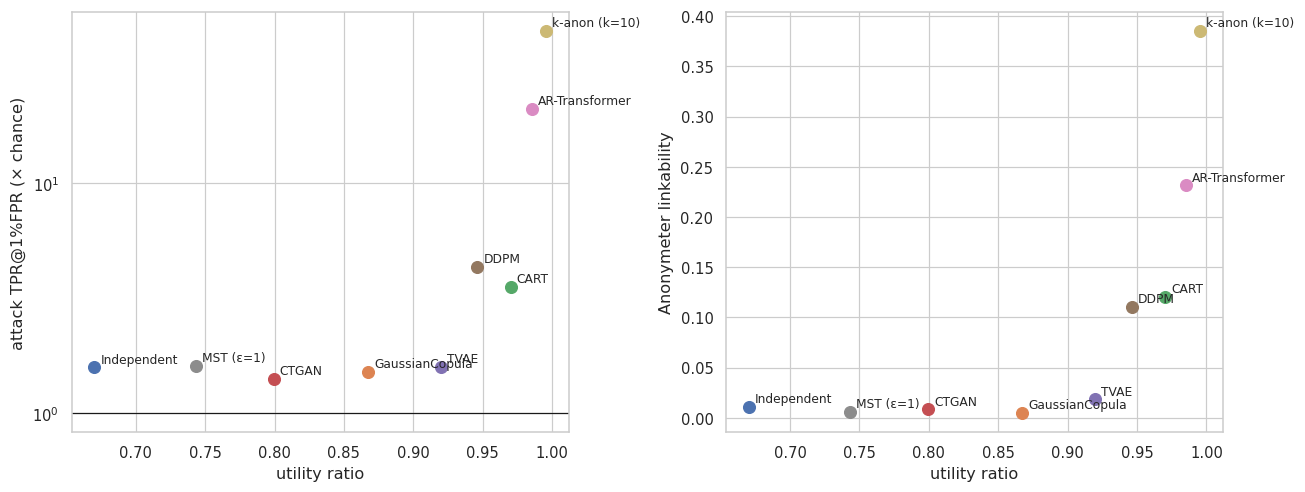

,util_ratio,pair,detect_auc,mia_auc_max,mia_tpr1_max,exact_match_syn,anon_link,anon_infer
dataset,,,,,,,,
Adult,0.987,0.972,0.572,0.571,0.021,0.074,0.027,0.035
Bank,0.979,0.961,0.605,0.570,0.023,0.000,0.017,0.005
COMPAS,0.991,0.979,0.572,0.571,0.022,0.567,0.054,0.232
Credit,0.984,0.942,0.703,0.570,0.024,0.000,0.012,0.015
Diabetes130,0.993,0.964,0.612,0.576,0.020,0.000,0.006,0.016
Fraud,0.987,0.910,0.900,0.536,0.015,0.000,0.029,0.135
German,0.979,0.935,0.692,0.800,0.561,0.019,0.617,0.606
Pima,0.985,0.829,0.711,0.780,0.545,0.005,0.593,0.574


In [6]:
P1 = pd.read_csv("partI/main_results.csv"); P1 = P1[P1.generator != "REAL (TRTR)"]
ALL = pd.concat([P1.assign(part="I"), X5.assign(part="II")], ignore_index=True)
plane = ALL.groupby("generator").agg(U=("util_ratio", "mean"), MIA=("mia_auc_max", "mean"), TPRx=("mia_tpr1_max", lambda x: np.mean(x) / 0.01),
                                     link=("anon_link", "mean"), runs=("util_ratio", "size")).reindex(ORDER)
plane.to_csv(f"{OUT}/tables/X5_plane_all8.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, col, lab in [(axes[0], "TPRx", "attack TPR@1%FPR (× chance)"), (axes[1], "link", "Anonymeter linkability")]:
    for g, r in plane.iterrows():
        if g == "Identity": continue
        ax.scatter(r.U, r[col], s=60); ax.annotate(g, (r.U, r[col]), fontsize=8, xytext=(4, 3), textcoords="offset points")
    ax.set_xlabel("utility ratio"); ax.set_ylabel(lab)
axes[0].set_yscale("log"); axes[0].axhline(1, c="k", lw=0.8); plt.tight_layout(); fig.savefig(f"{OUT}/figures/X5_plane_all8.png"); plt.show()
ar = ALL[ALL.generator == "AR-Transformer"].groupby("dataset")[["util_ratio", "pair", "detect_auc", "mia_auc_max", "mia_tpr1_max", "exact_match_syn", "anon_link", "anon_infer"]].mean()
ar.to_csv(f"{OUT}/tables/X5_ar_by_dataset.csv"); ar.round(3)

## Utility–privacy correlation on the new datasets (H13b) and representation checks

within-dataset rho(utility, MIA AUC) = 0.57 [0.41, 0.70]
within-dataset rho(pair fidelity, MIA AUC) = 0.65 [0.48, 0.77]


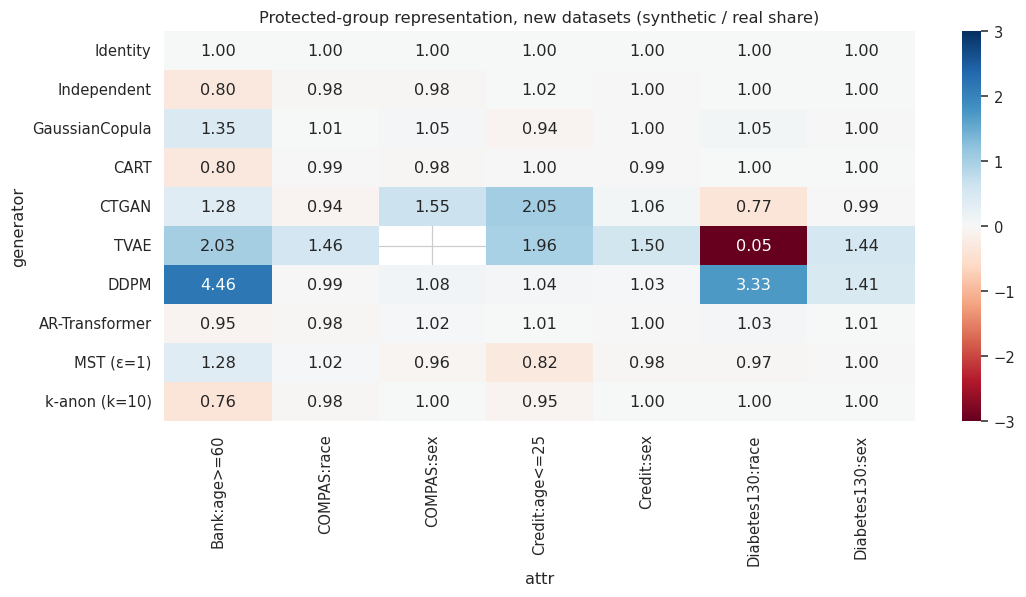

Notebook runtime: 154.6 min


In [7]:
GS = N[~N.generator.isin(["Identity", "k-anon (k=10)"])]
RK = GS.groupby("dataset")[["util_ratio", "mia_auc_max", "pair"]].rank(pct=True)
rho_u = sa.spearman_boot(RK.util_ratio, RK.mia_auc_max); rho_f = sa.spearman_boot(RK.pair, RK.mia_auc_max)
print(f"within-dataset rho(utility, MIA AUC) = {rho_u[0]:.2f} [{rho_u[1]:.2f}, {rho_u[2]:.2f}]")
print(f"within-dataset rho(pair fidelity, MIA AUC) = {rho_f[0]:.2f} [{rho_f[1]:.2f}, {rho_f[2]:.2f}]")
json.dump(dict(rho_util_mia=rho_u, rho_pair_mia=rho_f), open(f"{OUT}/tables/X5_rho_new.json", "w"))
rep = []
for _, r in N.iterrows():
    for c in [c for c in N.columns if c.endswith("|share") and not c.endswith("_real")]:
        a = c.split("|")[0]
        if pd.notna(r.get(c)) and pd.notna(r.get(f"{a}|share_real")):
            rep.append(dict(dataset=r.dataset, generator=r.generator, attr=f"{r.dataset}:{a}", ratio=r[c] / r[f"{a}|share_real"]))
REP = pd.DataFrame(rep).groupby(["generator", "attr"]).ratio.mean().unstack().reindex(ORDER); REP.to_csv(f"{OUT}/tables/X5_representation_new.csv")
fig, ax = plt.subplots(figsize=(11, 4.6))
sns.heatmap(np.log2(REP), annot=REP, fmt=".2f", cmap="RdBu", center=0, vmin=-3, vmax=3, ax=ax); ax.set_title("Protected-group representation, new datasets (synthetic / real share)")
fig.savefig(f"{OUT}/figures/X5_representation_new.png"); plt.show()
print(f"Notebook runtime: {(time.time()-T0)/60:.1f} min")